# LDA topic weights — what the fitted model says about each meeting

Visualises the output of `source/analysis/lda_cleaned/run_lda.py` (LDA on the team-cleaned transcripts).
Set `TAG` / `K` below to the run you want (`TAG` = the years folder, e.g. `y2022`).

**What is stored and where**
- `output/lda_cleaned/<TAG>/theta_meetings_k<K>.parquet` — one row per meeting: `id, leaid, year, split, t1…tK, modeled_tokens`.
  `t1…tK` are the meeting's topic weights (sum to 1; token-weighted average over its ~1,000-word chunks).
- `output/lda_cleaned/<TAG>/theta_chunks_k<K>.parquet` — same weights per chunk.
- `output/lda_cleaned/<TAG>/topics_k<K>.csv` — top 15 words per topic (by probability).
- `Datastore/DistrictView/derived/lda_cleaned/<TAG>/lda_k<K>.joblib` + `vectorizer.joblib` — the fitted model. Its
  `components_` is the full topic × word matrix (P(word | topic) after normalising), so any word list can be recomputed.

Topics are *not* named by the model: a topic is just a probability distribution over the vocabulary. Names are a human
reading of (a) its most probable words, (b) its most *distinctive* words, and (c) the meetings where it is heaviest.
Section 1 builds all three. **Clear outputs before committing** (section 1 prints meeting titles).

In [10]:
from pathlib import Path
import os, json, gzip
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "globals.json").exists())
os.chdir(REPO)  # all paths are relative to the repo root

TAG, K = "y2022", 15
RES = Path("output/lda_cleaned") / TAG                       # results (topic weights)
WORK = Path("Datastore/DistrictView/derived/lda_cleaned") / TAG  # fitted model + vectorizer
CLEAN_DIR = Path(os.environ.get("STAT236_CLEAN_DIR", "Datastore/cleaned_transcripts_2026_10_28"))
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)

T = [f"t{i}" for i in range(1, K + 1)]
meetings = pd.read_parquet(RES / f"theta_meetings_k{K}.parquet")
chunks = pd.read_parquet(RES / f"theta_chunks_k{K}.parquet")
print(f"{len(meetings):,} meetings, {len(chunks):,} chunks, {meetings.leaid.nunique():,} districts, K={K}")

# Chart style: one hue for magnitude, recessive axes/grid.
BLUE, BLUE_LIGHT, GRAY, INK, MUTED, GRID = "#2a78d6", "#9ec5f4", "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True, "font.size": 10,
})

1,237 meetings, 17,655 chunks, 714 districts, K=15


## 1. What each topic is about

Two word lists per topic:
- **Most probable** — highest P(word | topic). Dominated by words common everywhere ("board", "year", "students").
- **Most distinctive** — LDAvis *relevance* with λ = 0.6: `λ·log P(w|k) + (1−λ)·log[P(w|k) / P(w)]`, which down-weights
  words that are frequent in every topic (Sievert & Shirley 2014). Usually the better list for naming.

`label` (top 3 distinctive words) is used on the charts below; replace it with hand-written names once you have read the topics.

In [11]:
vec = joblib.load(WORK / "vectorizer.joblib")
model = joblib.load(WORK / f"lda_k{K}.joblib")
words = vec.get_feature_names_out()
beta = model.components_ / model.components_.sum(axis=1, keepdims=True)   # K x V, P(word | topic)

# Corpus-wide topic share (token-weighted) -> marginal word probability P(w).
topic_share = (meetings[T].mul(meetings.modeled_tokens, axis=0).sum() / meetings.modeled_tokens.sum()).values
p_word = topic_share @ beta
LAMBDA = 0.6
relevance = LAMBDA * np.log(beta) + (1 - LAMBDA) * np.log(beta / p_word)

topics = pd.DataFrame({
    "topic": T,
    "corpus_share": topic_share,
    "mean_meeting_weight": meetings[T].mean().values,
    "pct_meetings_over_5pct": (meetings[T] > .05).mean().values * 100,
    "top_probable": [", ".join(words[np.argsort(b)[::-1][:10]]) for b in beta],
    "top_distinctive": [", ".join(words[np.argsort(r)[::-1][:10]]) for r in relevance],
})
topics["label"] = [f"{t} · " + ", ".join(d.split(", ")[:3]) for t, d in zip(topics.topic, topics.top_distinctive)]
LABEL = dict(zip(topics.topic, topics.label))
with pd.option_context("display.max_colwidth", 90):
    display(topics.sort_values("corpus_share", ascending=False).round(3))

,topic,corpus_share,mean_meeting_weight,pct_meetings_over_5pct,top_probable,top_distinctive,label
7,t8,0.177,0.171,88.682,"want, really, things, people, say, did, mean, kind, need, lot","want, people, things, really, mean, say, kind, did, need, lot","t8 · want, people, things"
11,t12,0.140,0.120,62.975,"students, really, teachers, year, data, learning, work, student, support, grade","students, data, learning, teachers, really, level, student, grade, curriculum, support","t12 · students, data, learning"
1,t2,0.107,0.115,70.412,"board, students, district, community, work, great, mr, good, want, year","community, board, evening, district, great, students, education, tonight, members, dr","t2 · community, board, evening"
13,t14,0.100,0.105,71.625,"board, meeting, policy, committee, public, members, yes, th, agenda, superintendent","board, policy, meeting, committee, public, agenda, superintendent, members, th, policies","t14 · board, policy, meeting"
6,t7,0.082,0.070,42.522,"students, children, parents, people, kids, district, health, want, schools, community","children, parents, health, mask, child, students, people, kids, masks, safe","t7 · children, parents, health"
5,t6,0.066,0.083,54.487,"motion, second, yes, mr, aye, board, favor, item, approve, discussion","motion, second, aye, yes, mr, favor, approve, item, discussion, opposed","t6 · motion, second, aye"
14,t15,0.064,0.062,39.693,"year, budget, money, funding, dollars, increase, years, district, look, enrollment","budget, year, funding, increase, money, enrollment, dollars, positions, pay, funds","t15 · budget, year, funding"
3,t4,0.058,0.058,34.842,"building, project, work, new, projects, facilities, buildings, construction, things, high","project, building, facilities, projects, construction, buildings, facility, space, bid...","t4 · project, building, facilities"
9,t10,0.050,0.060,43.573,"year, day, yes, days, bus, time, summer, did, mr, week","bus, days, day, buses, summer, year, food, transportation, yes, lunch","t10 · bus, days, day"
12,t13,0.044,0.047,35.004,"students, grade, class, high, kids, year, student, really, classes, th","class, grade, students, classes, high, kids, music, college, student, band","t13 · class, grade, students"


Example meetings: the three meetings with the highest weight on each topic, with their YouTube titles
(read from the cleaned-transcript metadata). Titles are a quick sanity check — e.g. a "city council" topic whose top
meetings are not school-board meetings flags videos to exclude.

In [12]:
def load_titles(ids):
    out = {}
    for vid in ids:
        f = CLEAN_DIR / "metadata" / f"{vid}.json.gz"
        if f.exists():
            m = json.loads(gzip.decompress(f.read_bytes())).get("raw_metadata", {})
            out[vid] = m.get("title", "")
    return out

active = topics.loc[topics.corpus_share >= .01, "topic"].tolist()   # skip near-empty topics
top_ids = {t: meetings.nlargest(3, t)[["id", "leaid", t]] for t in active}
titles = load_titles({i for df in top_ids.values() for i in df.id})
rows = [dict(topic=LABEL[t], weight=round(r[t], 2), leaid=r.leaid, title=titles.get(r.id, "?"), url=f"https://youtu.be/{r.id}")
        for t, df in top_ids.items() for _, r in df.iterrows()]
with pd.option_context("display.max_colwidth", 80, "display.max_rows", 200):
    display(pd.DataFrame(rows))

,topic,weight,leaid,title,url
0,"t1 · state, percent, county",0.22,4217280,NPSD School Board Finance Committee Meeting 2-8-22,https://youtu.be/23Uy1Mal8JE
1,"t1 · state, percent, county",0.18,1200150,School Board Work Session 2/22/2022,https://youtu.be/-csKaOD-D2Q
2,"t1 · state, percent, county",0.18,3623580,"November 4, 2022 - Curriculum Committee Meeting",https://youtu.be/04I6D1k2ATQ
3,"t2 · community, board, evening",0.74,0634320,"San Diego Unified School District, Board of Education Meeting",https://youtu.be/-JlYm4qA8Qo
4,"t2 · community, board, evening",0.69,4900142,Board Oath of Office Ceremony 1/3/2022,https://youtu.be/1QlraxU0riA
5,"t2 · community, board, evening",0.64,3415360,Board of Education - Leonard Tobias Administration Building Dedication Ceremony,https://youtu.be/1o9tQoi9V74
6,"t4 · project, building, facilities",0.77,4211670,10/13/22 Finance and Facilities Committee Meeting,https://youtu.be/-Dhghr6nd4k
7,"t4 · project, building, facilities",0.58,4111720,St. Helens School Board Planning Session 5-18-2022,https://youtu.be/-zljqJRFJDk
8,"t4 · project, building, facilities",0.58,1803270,ECS Board of School Trustees’ Work Session 1/17/22,https://youtu.be/0e1MEZeVY_4
9,"t5 · street, parking, city",0.79,2504830,6 9 2022 Zoning Board of Appeals,https://youtu.be/0I0wIjMmNuo


## 2. How much of the corpus each topic takes

Bar = token-weighted share of all modeled words. Topics below 1% are effectively unused by the model
(a sign that K is too large for this sample, or that their words are generic filler).

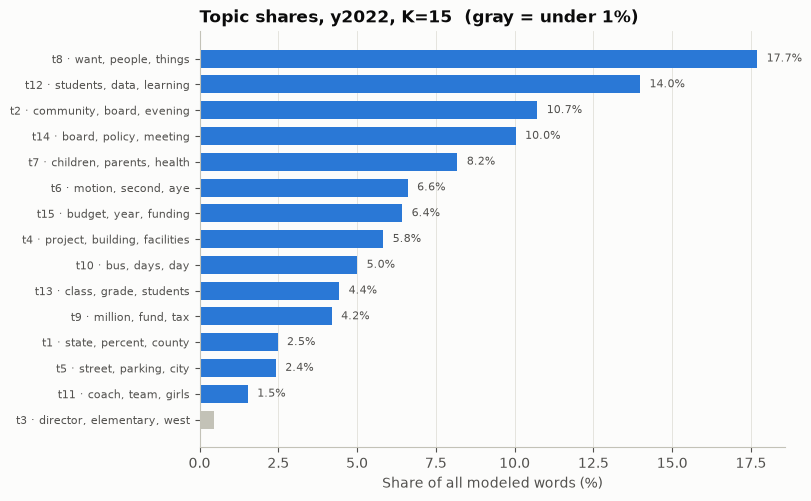

14 of 15 topics have at least 1% of words


In [13]:
order = topics.sort_values("corpus_share").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, .26 * K + 1), layout="constrained")
colors = [BLUE if s >= .01 else GRAY for s in order.corpus_share]
ax.barh(order.label, order.corpus_share * 100, color=colors, height=.7)
for y, s in enumerate(order.corpus_share):
    if s >= .01:
        ax.text(s * 100 + .3, y, f"{s * 100:.1f}%", va="center", fontsize=8, color=MUTED)
ax.set(xlabel="Share of all modeled words (%)", title=f"Topic shares, {TAG}, K={K}  (gray = under 1%)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
fig.savefig(FIG / f"topic_shares_k{K}.png", dpi=160)
plt.show()
print(f"{(topics.corpus_share >= .01).sum()} of {K} topics have at least 1% of words")

## 3. Distribution of meeting-level weights, per topic

One panel per topic (sorted by corpus share; shared x-axis 0–1, own y-axis). The y-axis is the share of meetings
in each 0.02-wide bin. A spike at 0 with a long right tail means the topic is concentrated in a few meetings; a hump away
from 0 means it is present in most meetings (procedural / general-talk topics look like this).

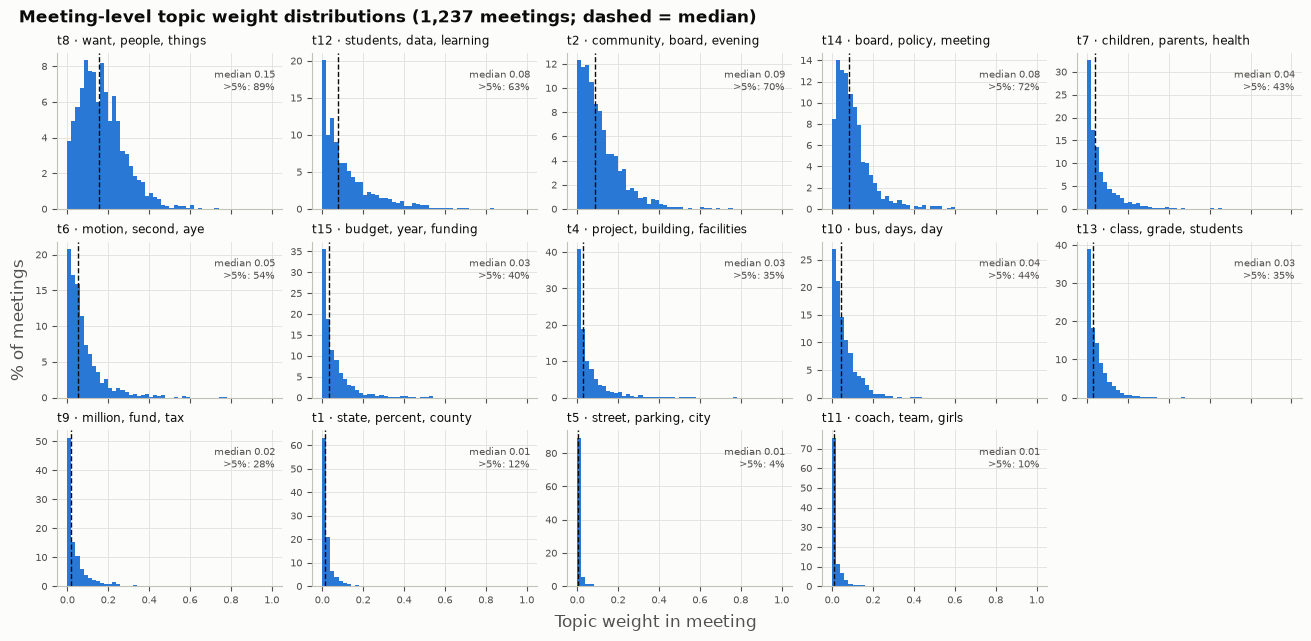

Not shown (1 topics under 1% of words, weight ~0 in every meeting): t3


In [14]:
SHOW_EMPTY = False   # True also draws topics under 1% of words (all mass at 0)
ranked = topics.sort_values("corpus_share", ascending=False)
by_share = ranked.topic.tolist() if SHOW_EMPTY else ranked.loc[ranked.corpus_share >= .01, "topic"].tolist()
ncol = 5
nrow = int(np.ceil(len(by_share) / ncol))
bins = np.arange(0, 1.0001, .02)
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.1 * nrow), sharex=True, layout="constrained", squeeze=False)
for ax, t in zip(axes.ravel(), by_share):
    w = meetings[t]
    ax.hist(w, bins=bins, weights=np.full(len(w), 100 / len(w)), color=BLUE if topic_share[T.index(t)] >= .01 else GRAY)
    ax.axvline(w.median(), color=INK, lw=1, ls="--")
    ax.set_title(LABEL[t], fontsize=8.5, fontweight="normal")
    ax.text(.97, .9, f"median {w.median():.2f}\n>5%: {(w > .05).mean():.0%}", transform=ax.transAxes, ha="right", va="top",
            fontsize=7.5, color=MUTED)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(by_share):]:
    ax.set_visible(False)
fig.supxlabel("Topic weight in meeting", color=MUTED)
fig.supylabel("% of meetings", color=MUTED)
fig.suptitle(f"Meeting-level topic weight distributions ({len(meetings):,} meetings; dashed = median)", x=.01, ha="left",
             fontweight="bold")
fig.savefig(FIG / f"weight_distributions_k{K}.png", dpi=160)
plt.show()
empty = [t for t in ranked.topic if t not in by_share]
if empty:
    print(f"Not shown ({len(empty)} topics under 1% of words, weight ~0 in every meeting):", ", ".join(empty))

Same information compactly for the active topics: box = middle 50% of meetings, whiskers = 5th–95th percentile.

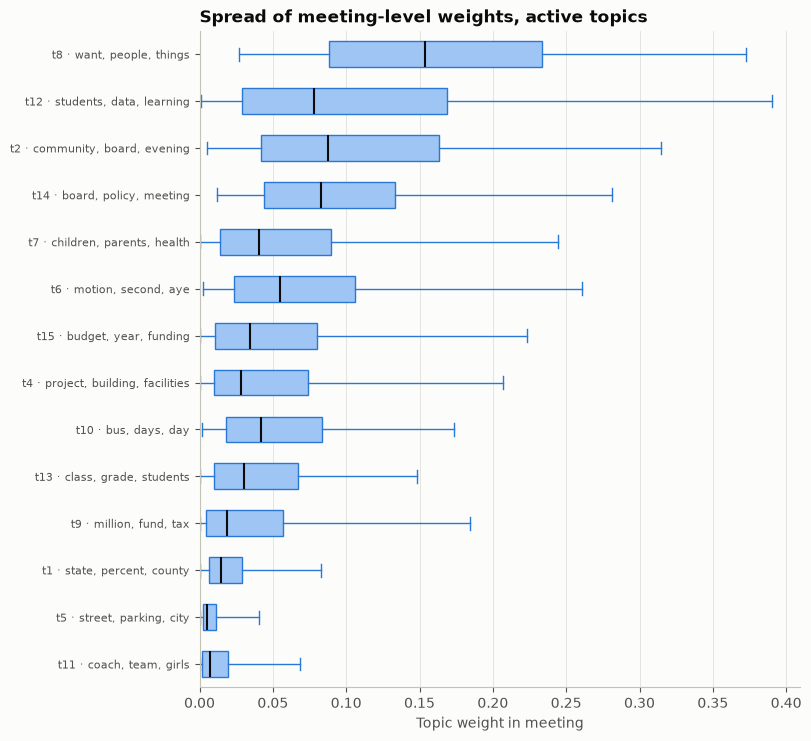

In [15]:
act = topics.loc[topics.corpus_share >= .01].sort_values("corpus_share").topic.tolist()
fig, ax = plt.subplots(figsize=(8, .45 * len(act) + 1), layout="constrained")
ax.boxplot([meetings[t] for t in act], orientation="horizontal", whis=(5, 95), showfliers=False, widths=.55, patch_artist=True,
           boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE), medianprops=dict(color=INK, lw=1.5),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_yticks(range(1, len(act) + 1), [LABEL[t] for t in act], fontsize=8)
ax.set(xlabel="Topic weight in meeting", xlim=(0, None), title="Spread of meeting-level weights, active topics")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / f"weight_boxplots_k{K}.png", dpi=160)
plt.show()

## 4. How mixed are meetings?

Largest single-topic weight per meeting and per chunk. Meetings average over many chunks, so they are more mixed
(lower max) than individual ~1,000-word chunks. The dominant-topic counts show which topic "wins" most meetings.

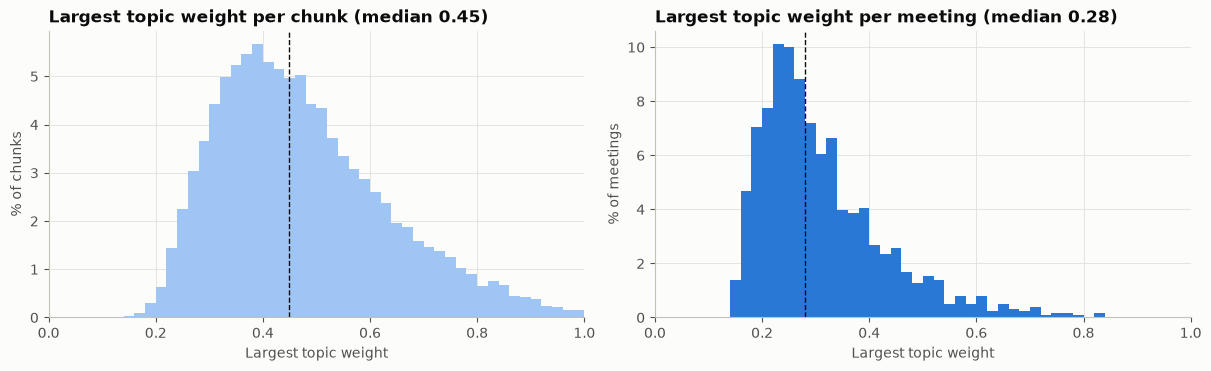

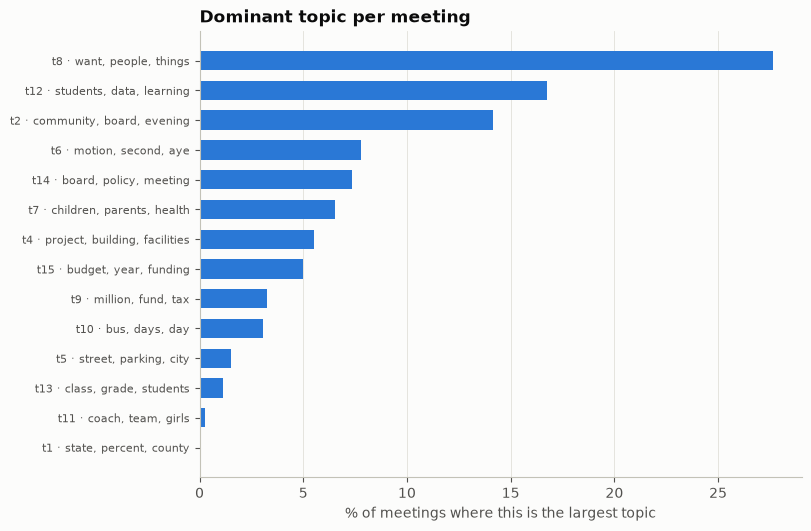

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
for a, (name, df, c) in zip(ax, [("chunks", chunks, BLUE_LIGHT), ("meetings", meetings, BLUE)]):
    mx = df[T].max(axis=1)
    a.hist(mx, bins=np.arange(0, 1.0001, .02), weights=np.full(len(mx), 100 / len(mx)), color=c)
    a.axvline(mx.median(), color=INK, lw=1, ls="--")
    a.set(xlim=(0, 1), xlabel="Largest topic weight", ylabel=f"% of {name}",
          title=f"Largest topic weight per {name[:-1]} (median {mx.median():.2f})")
dom = meetings[T].idxmax(axis=1).value_counts()
ax[1].figure.savefig(FIG / f"max_weight_k{K}.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, .3 * len(dom) + 1), layout="constrained")
dom = dom.sort_values()
ax.barh([LABEL[t] for t in dom.index], dom.values / len(meetings) * 100, color=BLUE, height=.65)
ax.set(xlabel="% of meetings where this is the largest topic", title="Dominant topic per meeting")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
fig.savefig(FIG / f"dominant_topic_k{K}.png", dpi=160)
plt.show()

## 5. Toward networks: district profiles and topic co-occurrence

**District profiles** average each district's meetings equally (so districts with long meetings don't dominate).
These vectors are the natural node attributes for a district–district similarity network.

**Topic correlation** across meetings (active topics only): positive = the two topics tend to appear in the same
meetings. Weights sum to 1, so negative correlations are partly mechanical; read the positive cells.

714 districts; meetings per district: median 1, 119 districts with >= 3 meetings


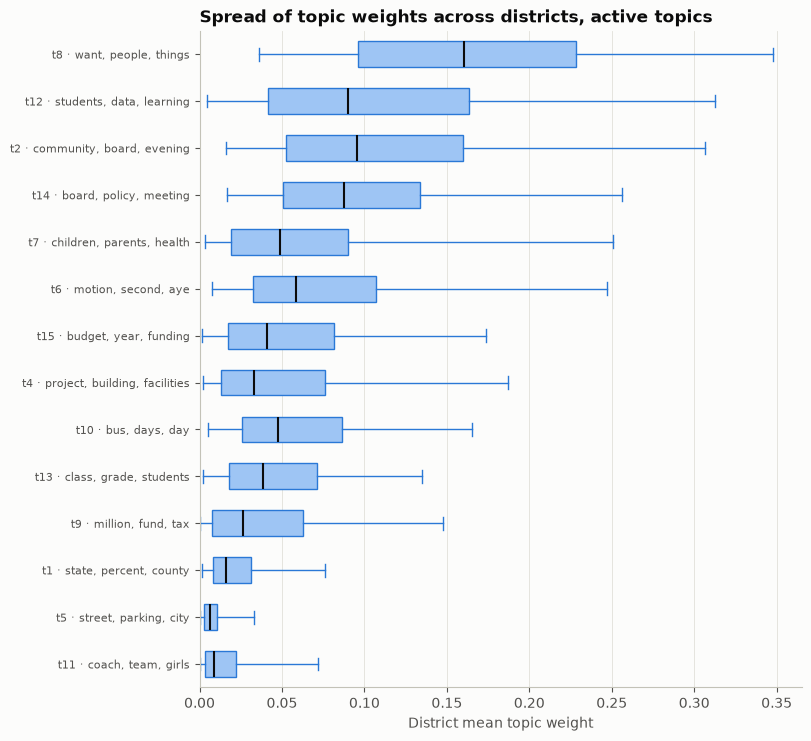

In [17]:
district = meetings.groupby("leaid")[T].mean()
n_meet = meetings.groupby("leaid").size()
print(f"{len(district):,} districts; meetings per district: median {n_meet.median():.0f}, "
      f"{(n_meet >= 3).sum():,} districts with >= 3 meetings")

fig, ax = plt.subplots(figsize=(8, .45 * len(act) + 1), layout="constrained")
ax.boxplot([district[t] for t in act], orientation="horizontal", whis=(5, 95), showfliers=False, widths=.55, patch_artist=True,
           boxprops=dict(facecolor=BLUE_LIGHT, edgecolor=BLUE), medianprops=dict(color=INK, lw=1.5),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
ax.set_yticks(range(1, len(act) + 1), [LABEL[t] for t in act], fontsize=8)
ax.set(xlabel="District mean topic weight", xlim=(0, None), title="Spread of topic weights across districts, active topics")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / f"district_boxplots_k{K}.png", dpi=160)
plt.show()

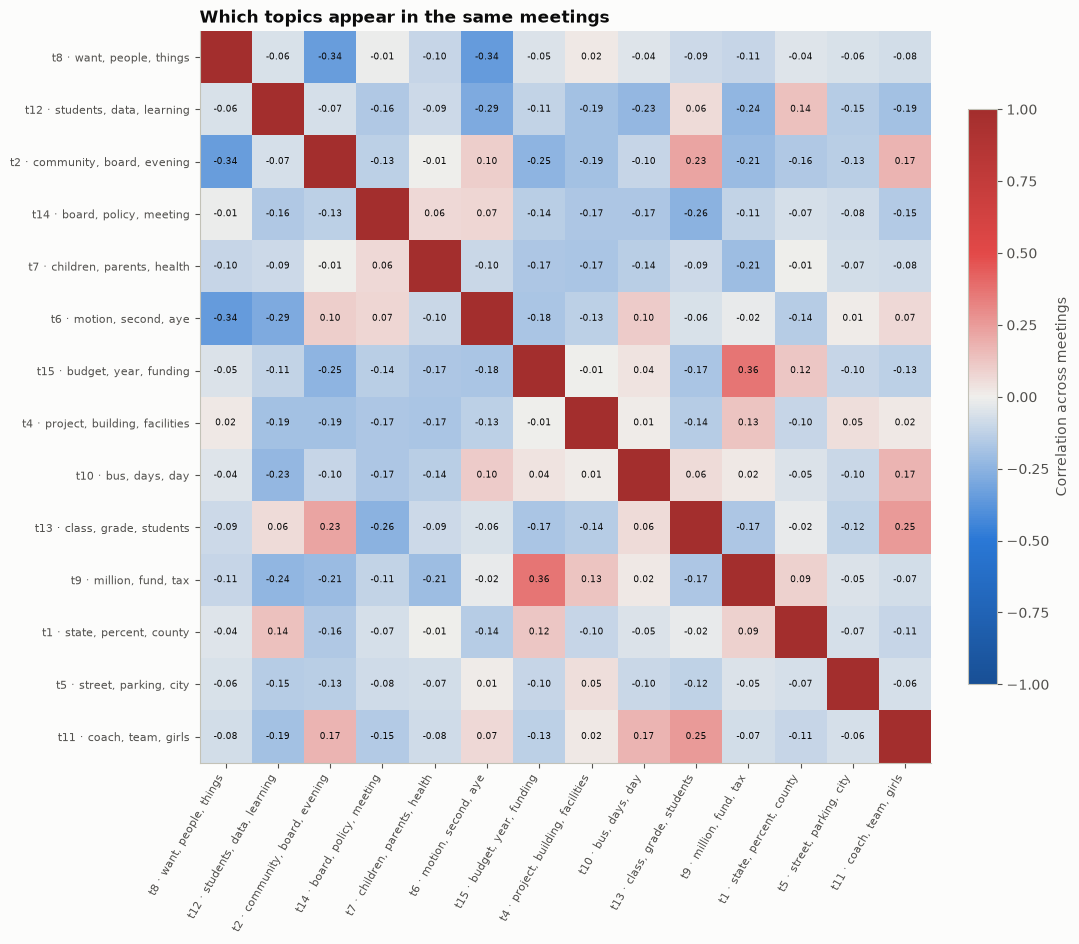

In [18]:
from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a32e2d"])
act_desc = act[::-1]
corr = meetings[act_desc].corr()
fig, ax = plt.subplots(figsize=(.55 * len(act) + 3, .55 * len(act) + 2), layout="constrained")
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
labels = [LABEL[t] for t in act_desc]
ax.set_xticks(range(len(act)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(act)), labels, fontsize=8)
ax.grid(False)
for i in range(len(act)):
    for j in range(len(act)):
        if i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(corr.iloc[i, j]) > .5 else INK)
fig.colorbar(im, ax=ax, shrink=.7, label="Correlation across meetings")
ax.set_title("Which topics appear in the same meetings")
fig.savefig(FIG / f"topic_correlation_k{K}.png", dpi=160)
plt.show()

## Notes
- One-year test run (partial upload of the cleaned data); topic numbers are local to this fit and change if the model is refit.
- Weights are shares of *modeled* words (after stopwords and vocabulary filtering), not shares of speaking time.
- Figures are saved to `output/lda_cleaned/<TAG>/figures/`.